# San Francisco Housing Production and Family Zoning Plan

## Imports — all in one place

In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns


<a id="step-1"></a>
## Step 1 — Clean and filter the data

### 1a. Housing Production

In [2]:
# Read each permit as text, especially BlockLot (leading zeros are meaningful).
housing = pd.read_csv("data/raw/housing_production.csv", dtype={"bpa": str, "blocklot": str})
housing

,source_row_id,bpa,address,description,pts_existing_units,pts_proposed_units,proposed_units,net_units,net_units_completed,adu_legalization_units,...,plan_area,form_no,permit_type,issued_date,authorization_date,zoning_district,project_affordability_type,bmr_reporting_year,blocklot,ppts_project_id
0,row-uj95-csqk.dju3,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,...,NaN,3,Site Permit,2007-04-27T00:00:00.000,2007-04-27T00:00:00.000,P,NaN,2010,1300001,NaN
1,row-ntav.j4q3-gvpk,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T11:30:17.000,RH-2,NaN,2008,5828012,2007.0150
2,row-8kwi~kmki~667e,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T10:59:39.000,RH-2,NaN,2008,5828011,NaN
3,row-knk4~b77d~zswv,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2004-08-31T00:00:00.000,2004-09-01T11:41:51.000,RH-2,NaN,2005,1855045,2003.0545
4,row-6snx-hhan_j82j,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,...,NaN,2,Full Building Permit,2005-01-05T00:00:00.000,2005-01-05T00:00:00.000,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6155,row-xxzz~wz7e~g8r7,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,...,NaN,2,Site Permit,2006-03-28T00:00:00.000,2006-08-16T12:07:27.000,RH-2,100% Affordable,2014,4991277,1999.233
6156,row-xf6x_ve62.znz9,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,...,NaN,2,Site Permit,2001-08-02T00:00:00.000,2001-08-03T16:56:26.000,RM-1,NaN,2005,0092044,2002.0792
6157,row-xh2y~5vmg-x6ue,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-31T14:21:57.000,RH-2,NaN,2008,5828013,2007.0151
6158,row-c84k_ck9c~rb8t,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,...,NaN,1,Full Building Permit,NaN,2023-02-01T00:00:00.000,P,NaN,2023,0348009,2025-008348PRX


In [3]:
# Housing Production data cleaning

# covert to datetime & numeric
housing["first_completion_date"] = pd.to_datetime(housing["first_completion_date"])
housing["net_units_completed"] = pd.to_numeric(housing["net_units_completed"])

# Keep the study period, known nonzero changes, and all housing losses.
in_period = (housing["first_completion_date"] >= "2005-01-01") & (housing["first_completion_date"] < "2026-01-01")
valid_units = (~housing["net_units_completed"].isna()) & (housing["net_units_completed"] != 0)

selected = housing.loc[in_period & valid_units].copy()

# rename each column
housing_production_filtered = selected.rename(columns={
    "bpa": "BPA", 
    "address": "Address", 
    "blocklot": "BlockLot",
    "net_units_completed": "Net Units Completed",
    "first_completion_date": "First Completion Date", "latest_completion_date": "Latest Completion Date"
})

In [4]:
# save filtered housing production data as csv file

housing_production_filtered.to_csv("data/processed/housing_production_filtered.csv", index=False)

print("Study records:", len(housing_production_filtered))
print("Source net housing additions:", housing_production_filtered["Net Units Completed"].sum())

housing_production_filtered


Study records: 5981
Source net housing additions: 57982


,source_row_id,BPA,Address,description,pts_existing_units,pts_proposed_units,proposed_units,net_units,Net Units Completed,adu_legalization_units,...,plan_area,form_no,permit_type,issued_date,authorization_date,zoning_district,project_affordability_type,bmr_reporting_year,BlockLot,ppts_project_id
0,row-uj95-csqk.dju3,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,...,NaN,3,Site Permit,2007-04-27T00:00:00.000,2007-04-27T00:00:00.000,P,NaN,2010,1300001,NaN
1,row-ntav.j4q3-gvpk,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T11:30:17.000,RH-2,NaN,2008,5828012,2007.0150
2,row-8kwi~kmki~667e,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T10:59:39.000,RH-2,NaN,2008,5828011,NaN
3,row-knk4~b77d~zswv,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2004-08-31T00:00:00.000,2004-09-01T11:41:51.000,RH-2,NaN,2005,1855045,2003.0545
4,row-6snx-hhan_j82j,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,...,NaN,2,Full Building Permit,2005-01-05T00:00:00.000,2005-01-05T00:00:00.000,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6155,row-xxzz~wz7e~g8r7,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,...,NaN,2,Site Permit,2006-03-28T00:00:00.000,2006-08-16T12:07:27.000,RH-2,100% Affordable,2014,4991277,1999.233
6156,row-xf6x_ve62.znz9,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,...,NaN,2,Site Permit,2001-08-02T00:00:00.000,2001-08-03T16:56:26.000,RM-1,NaN,2005,0092044,2002.0792
6157,row-xh2y~5vmg-x6ue,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-31T14:21:57.000,RH-2,NaN,2008,5828013,2007.0151
6158,row-c84k_ck9c~rb8t,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,...,NaN,1,Full Building Permit,NaN,2023-02-01T00:00:00.000,P,NaN,2023,0348009,2025-008348PRX


### 1b. Land Use cleaning from `clean_sf_land_use.py`

In [5]:
# Read parcel IDs as strings so the Land Use join keeps leading zeros.
land = pd.read_csv("data/raw/San_Francisco_Land_Use.csv",dtype={"mapblklot": str, "residential_units": str}, low_memory=False)
land

,the_geom,LUDB_id,centroid_latitude,centroid_longitude,residential_units,residential_units_special,cie,med,mips,retail,...,parking_lot,garage,open_space,residential_use,geography_type,mapblklot,major_multiphase_project,special_jurisdiction,data_as_of,data_loaded_at
0,"MULTIPOLYGON (((-122.388813 37.78295, -122.389...",DAGid_0_20260817,37.783644,-122.388816,177,0,0,0,0,59221,...,False,False,False,NaN,multiple_parcels,"'3791002', '3791001', '3790001'",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
1,"MULTIPOLYGON (((-122.388513 37.784828, -122.38...",DAGid_1_20260817,37.784916,-122.389736,863,0,0,0,0,0,...,False,False,False,NaN,multiple_parcels,"'3773577', '3773300A', '3773291', '3773200A', ...",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
2,"MULTIPOLYGON (((-122.420419 37.805374, -122.42...",DAGid_2_20260817,37.805473,-122.420596,24,0,0,0,0,0,...,False,False,False,NaN,multiple_parcels,"'0026T001A', '0026028'",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
3,"MULTIPOLYGON (((-122.431644 37.782376, -122.43...",DAGid_3_20260817,37.782041,-122.431272,120,0,0,0,0,0,...,False,False,False,NaN,multiple_parcels,"'0732001', '0732002', '0732004', '0732028', '0...",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
4,"MULTIPOLYGON (((-122.421594 37.780454, -122.42...",DAGid_4_20260817,37.780507,-122.421121,0,0,0,0,270768,0,...,False,False,False,NaN,multiple_parcels,"'0767005', '0767009', '0767007', '0767001', '0...",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153760,"MULTIPOLYGON (((-122.389035869 37.720764617, -...",DAGid_165198_20260817,37.720837,-122.388865,2,0,0,0,0,0,...,False,False,False,NaN,parcel,4909002,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
153761,"MULTIPOLYGON (((-122.463917797 37.711180579, -...",DAGid_165200_20260817,37.711214,-122.464091,3,0,0,0,0,0,...,False,False,False,NaN,parcel,7135022,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
153762,"MULTIPOLYGON (((-122.503286888 37.764168657, -...",DAGid_165201_20260817,37.764139,-122.503185,2,0,0,0,0,0,...,False,False,False,NaN,parcel,1707001,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
153763,"MULTIPOLYGON (((-122.404650526 37.780491839, -...",DAGid_165202_20260817,37.780605,-122.404704,8,0,0,0,0,0,...,False,False,False,NaN,parcel,3732096,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM


In [6]:
# Flag missing fields before applying the original cleaning rule.
land["missing_parcel_id"] = land["mapblklot"].isna()
land["missing_residential_units"] = land["residential_units"].isna()
land = land.loc[~land["missing_parcel_id"]].copy()
land["residential_units"] = land["residential_units"].fillna("0")
clean_unit_values = []
for value in land["residential_units"]:
    clean_unit_values.append(int(value.replace(",", "")))
land["residential_units"] = clean_unit_values

# Retain the original teammate's parcel-conflict decisions.
AUDIT_RETAIN = {
    "1761053": 2, "3180214": 71, "6310010": 69, "6310011": 108,
    "6311014": 4, "6311016": 170, "6311026": 4, "7138055": 1,
    "4285B003": 1, "4285B004": 157
}
for parcel_id, retained_units in AUDIT_RETAIN.items():
    remove = (land["mapblklot"] == parcel_id) & (land["residential_units"] != retained_units)
    land = land.loc[~remove].copy()
land = land.drop_duplicates(subset="mapblklot", keep="first")
land = land[["mapblklot", "centroid_latitude", "centroid_longitude", "residential_units","geography_type", "missing_parcel_id", "missing_residential_units"]]

In [7]:
# save filtered land as sf_land_use_clean.csv
land.to_csv("data/processed/sf_land_use_clean.csv", index=False)
print("Cleaned Land Use records:", len(land))

land.head()

Cleaned Land Use records: 153754


,mapblklot,centroid_latitude,centroid_longitude,residential_units,geography_type,missing_parcel_id,missing_residential_units
0,"'3791002', '3791001', '3790001'",37.783644,-122.388816,177,multiple_parcels,False,False
1,"'3773577', '3773300A', '3773291', '3773200A', ...",37.784916,-122.389736,863,multiple_parcels,False,False
2,"'0026T001A', '0026028'",37.805473,-122.420596,24,multiple_parcels,False,False
3,"'0732001', '0732002', '0732004', '0732028', '0...",37.782041,-122.431272,120,multiple_parcels,False,False
4,"'0767005', '0767009', '0767007', '0767001', '0...",37.780507,-122.421121,0,multiple_parcels,False,False


<a id="step-2"></a>
## Step 2 — Give each permit a location

### 2a. Exact individual-parcel join — from `tabular_join.py`

Select Land Use rows marked parcel and left-merge Housing Production BlockLot with Land Use mapblklot. Copy the published latitude and longitude, while retaining every housing record. Only coordinates are attached; Land Use stock is never added to permit-level net unit changes.


In [8]:
# Join Housing Production to single-parcel Land Use centroids by BlockLot.
single = land.loc[land["geography_type"] == "parcel", ["mapblklot", "centroid_latitude", "centroid_longitude"]].rename(columns={"centroid_latitude": "latitude", "centroid_longitude": "longitude"})

located = housing_production_filtered.merge(single, left_on="BlockLot", right_on="mapblklot", how="left")
located = located.drop(columns="mapblklot")
single_match = (~located["latitude"].isna()) & (~located["longitude"].isna())
located["match_status"] = "unmatched"
located["match_note"] = "no_parcel_match"
located.loc[single_match, "match_status"] = "matched_single"
located.loc[single_match, "match_note"] = "parcel_centroid"


### 2b. Multi-parcel records (simple, cautious matching)

Some Land Use rows contain **several quoted BlockLot IDs**, for example `'0123001', '0123002'`. We accept **only complete, quoted lists** with coordinates and **only one distinct candidate location per BlockLot**. Incomplete lists are skipped instead of guessing.

This step can locate a housing record at the **shared group centroid**, not necessarily the exact building. It does not change net housing units.

In [9]:
multi = land.loc[land["geography_type"] == "multiple_parcels"].copy()
rows = []

for raw, lat, lon in zip(multi["mapblklot"], multi["centroid_latitude"], multi["centroid_longitude"]):
    if pd.isna(lat) or pd.isna(lon):
        continue

    parts = str(raw).split(",")
    parcel_ids = []
    complete_list = True
    for part in parts:
        part = part.strip()
        if len(part) >= 3 and part[0] == "'" and part[-1] == "'":
            parcel_ids.append(part[1:-1])
        else:
            complete_list = False

    if complete_list and len(parcel_ids) >= 2:
        for parcel_id in parcel_ids:
            rows.append([parcel_id, lat, lon])

multi_candidates = pd.DataFrame(rows, columns=["BlockLot", "multi_latitude", "multi_longitude"])
multi_candidates = multi_candidates.drop_duplicates()

# One BlockLot may appear at more than one location: do not guess which is right.
counts = multi_candidates.groupby("BlockLot").size().reset_index(name="locations")
multi_candidates = multi_candidates.merge(counts, on="BlockLot", how="left")
multi_candidates = multi_candidates.loc[multi_candidates["locations"] == 1].copy()

# A left merge keeps every housing record.
located = located.merge(
    multi_candidates[["BlockLot", "multi_latitude", "multi_longitude"]],
    on="BlockLot", how="left"
)
fill = (located["match_status"] == "unmatched") & located["multi_latitude"].notna() & located["multi_longitude"].notna()
located.loc[fill, "latitude"] = located.loc[fill, "multi_latitude"]
located.loc[fill, "longitude"] = located.loc[fill, "multi_longitude"]
located.loc[fill, "match_status"] = "matched_multi_centroid"
located.loc[fill, "match_note"] = "Land Use group centroid"
located = located.drop(columns=["multi_latitude", "multi_longitude"])

print("Multi-parcel matches:", fill.sum())
print("Housing records still unmatched:", (located["match_status"] == "unmatched").sum())

Multi-parcel matches: 16
Housing records still unmatched: 2027


In [10]:
# Save the initial Land Use matches before supplemental DBI coordinates.
located.to_csv("data/processed/housing_production_located.csv", index=False)

print(located["match_status"].value_counts())
located.head()

match_status
matched_single            3938
unmatched                 2027
matched_multi_centroid      16
Name: count, dtype: int64


,source_row_id,BPA,Address,description,pts_existing_units,pts_proposed_units,proposed_units,net_units,Net Units Completed,adu_legalization_units,...,authorization_date,zoning_district,project_affordability_type,bmr_reporting_year,BlockLot,ppts_project_id,latitude,longitude,match_status,match_note
0,row-uj95-csqk.dju3,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,...,2007-04-27T00:00:00.000,P,NaN,2010,1300001,NaN,NaN,NaN,unmatched,no_parcel_match
1,row-ntav.j4q3-gvpk,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,2006-08-29T11:30:17.000,RH-2,NaN,2008,5828012,2007.0150,NaN,NaN,unmatched,no_parcel_match
2,row-8kwi~kmki~667e,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,...,2006-08-29T10:59:39.000,RH-2,NaN,2008,5828011,NaN,NaN,NaN,unmatched,no_parcel_match
3,row-knk4~b77d~zswv,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,...,2004-09-01T11:41:51.000,RH-2,NaN,2005,1855045,2003.0545,NaN,NaN,unmatched,no_parcel_match
4,row-6snx-hhan_j82j,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,...,2005-01-05T00:00:00.000,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051,NaN,NaN,unmatched,no_parcel_match


### 2c. Simple coordinate recovery

- Keep original Land Use coordinates.
- For still-unmatched records, use a DBI **primary-address coordinate** when its `BPA` has exactly **one unique coordinate**.
- Keep everything else unmatched; never invent a position.

    The raw DBI file is a local JSON input.


In [11]:
# Remember original Land Use matching results before DBI fills missing points.
located["land_use_match_status"] = located["match_status"]

original_unmatched = located.loc[located["match_status"] == "unmatched"].copy()
print("Before DBI - unmatched records:", len(original_unmatched))
print("Before DBI - unmatched net units:", original_unmatched["Net Units Completed"].sum())

Before DBI - unmatched records: 2027
Before DBI - unmatched net units: 39195


In [12]:
# Step 2c: Get permit coordinates from DBI

# Read DBI data
with open("data/raw/dbi_all_study_permit_coordinates.json", encoding="utf-8") as file:
    dbi_records = json.load(file)

# Keep primary-address records with coordinates
rows = []

for record in dbi_records:

    if record.get("primary_address_flag") == "Y" and record.get("location") is not None:
        coordinates = record["location"].get("coordinates")
        
        if coordinates is not None and len(coordinates) >= 2:
            rows.append([
                str(record["permit_number"]),  # Building Permit Application number (BPA)
                coordinates[1],               # Latitude (second value)
                coordinates[0]                # Longitude (first value)
            ])


# Create a DataFrame
dbi = pd.DataFrame(rows, columns=["BPA", "dbi_latitude", "dbi_longitude"])

# Remove identical records
dbi = dbi.drop_duplicates()

# Remove permits with multiple different locations
dbi = dbi.drop_duplicates(subset="BPA", keep=False)

print("Unique DBI permit coordinates:", len(dbi))


Unique DBI permit coordinates: 5955


In [13]:
# Step 2c: Fill missing housing coordinates using DBI

# Join DBI coordinates to Housing Production using BPA.
located = located.merge(dbi, on="BPA", how="left")

# Find records with missing coordinates that DBI can provide.
dbi_fill = ((located["latitude"].isna() | located["longitude"].isna()) & located["dbi_latitude"].notna()& located["dbi_longitude"].notna())

# Fill missing housing locations with DBI coordinates.
located.loc[dbi_fill, "latitude"] = located.loc[dbi_fill, "dbi_latitude"]
located.loc[dbi_fill, "longitude"] = located.loc[dbi_fill, "dbi_longitude"]

# Update the matching results.
located.loc[dbi_fill, "match_status"] = "matched_dbi"
located.loc[dbi_fill, "match_note"] = "DBI primary address; one unique coordinate"

# Remove temporary DBI columns.
located = located.drop(columns=["dbi_latitude", "dbi_longitude"])

# Record the final location source based on match_status.
located["location_source"] = located["match_status"].replace({
    "matched_single": "land_use_single",
    "matched_multi_centroid": "land_use_group_centroid",
    "matched_dbi": "dbi_primary",
    "unmatched": "unlocated"
})

# Check the final matching results.
print("Records recovered using DBI:", dbi_fill.sum())
print("Total housing records:", len(located))
print(located["location_source"].value_counts())

print("Net units still unmatched:", located.loc[located["match_status"] == "unmatched", "Net Units Completed"].sum())


Records recovered using DBI: 2005
Total housing records: 5981
location_source
land_use_single            3938
dbi_primary                2005
unlocated                    22
land_use_group_centroid      16
Name: count, dtype: int64
Net units still unmatched: 826


In [14]:
# Preserve unmatched records for the professor's validation checks.
unmatched = located.loc[located["match_status"] == "unmatched"].copy()
unmatched.to_csv("data/processed/unmatched_housing_records.csv", index=False)
located.to_csv("data/processed/housing_production_located_recovered.csv", index=False)

location_summary = located.groupby("location_source")["Net Units Completed"].agg(["count", "sum"])
location_summary.to_csv("data/processed/location_source_summary.csv")
location_summary

,count,sum
location_source,,
dbi_primary,2005,38369
land_use_group_centroid,16,2651
land_use_single,3938,16136
unlocated,22,826


<a id="step-3"></a>
## Step 3 — Assign located housing records to census tracts

Use `Point` and `gpd.sjoin()` to place each housing record inside a 2020 Census Tract. **The spatial join is based on coordinates; unmatched rows remain in `detailed` but have no GEOID.**

Use the source's unique `source_row_id` to merge the GEOID back (not `BPA`, which might be repeated). Report the fraction of records and **net housing units** that remain unassigned. This is essential because we simplified Step 2c; do **not** describe the output as a complete citywide map when records lack a tract.

In [15]:
# Step 3: Assign Housing Production Records to 2020 Census Tracts(spatial join)

# Import Point to create geographic points from coordinates.
from shapely.geometry import Point

# Load the 2020 Census Tract 
tracts = gpd.read_file("data/raw/census_2020_tracts_raw.geojson")

# Rename the columns to match the names used in our project.
tracts = tracts.rename(columns={"geoid": "GEOID", "name": "NAME"})

# Convert tract geometries to EPSG:4326 (longitude and latitude).
tracts = tracts.to_crs("EPSG:4326")

# Give each housing record a unique ID for the tract join.
located["source_row_id"] = range(len(located))
has_coordinates = located["latitude"].notna() & located["longitude"].notna()

# Keep the source_row_id of records with valid coordinates.
# source_row_id identifies each original Housing Production row.
point_rows = located.loc[located["latitude"].notna() & located["longitude"].notna(), ["source_row_id"]].copy()

# Create an empty list to store geographic Point objects.
points = []

# Loop through the longitude and latitude of each located housing record.
# zip() pairs each longitude with its corresponding latitude.
for lon, lat in zip(located.loc[has_coordinates, "longitude"], located.loc[has_coordinates, "latitude"]):

    # Create a geographic point and add it to the list.
    # Point() takes longitude first, then latitude.
    points.append(Point(lon, lat))

# Create a GeoDataFrame containing the housing points.
# Each row has a source_row_id and a Point geometry.
housing_points = gpd.GeoDataFrame(
    point_rows,
    geometry=points,
    crs="EPSG:4326"
)

# Spatial Join: assign each housing point to a Census Tract.
# "within" checks whether the point falls inside a tract polygon.
# how="left" keeps all housing points, even if no tract is matched.
housing_joined = gpd.sjoin(
    housing_points,
    tracts[["GEOID", "geometry"]],
    how="left",
    predicate="within"
)

# Count the number of housing records with coordinates.
print("Housing points:", len(housing_points))

# Check the number of rows after the Spatial Join.
# This helps identify whether any housing points matched multiple tracts.
print("Rows after spatial join:", len(housing_joined))

# Check whether source_row_id is duplicated in the original located DataFrame.
# Each source_row_id should identify one Housing Production record.
print("Repeated source IDs after spatial join:", housing_joined["source_row_id"].duplicated().sum())

# Join the Census Tract GEOID back to the original Housing Production records.
# Match using source_row_id, keeps all original records, including those without a GEOID.
detailed = located.merge(housing_joined[["source_row_id", "GEOID"]], on="source_row_id",how="left")

# Save the Housing Production records with their assigned Census Tract GEOIDs.
detailed.to_csv("data/processed/housing_production_with_tract.csv",index=False)

# Compare Land Use matching and final DBI + Spatial Join
# Identify matched records at each stage
land_match = detailed["land_use_match_status"] != "unmatched"
final_match = detailed["GEOID"].notna()

# Housing units
units = detailed["Net Units Completed"]

# Create a summary table
join_summary = pd.DataFrame({
    "stage": ["Land Use only", "After DBI + tract join"],
    "assigned_records": [land_match.sum(), final_match.sum()],
    "unassigned_records": [(~land_match).sum(), (~final_match).sum()],
    "assigned_net_units": [units[land_match].sum(), units[final_match].sum()],
    "unassigned_net_units": [units[~land_match].sum(), units[~final_match].sum()]
})

# Save and display results
join_summary.to_csv("data/processed/housing_join_summary.csv", index=False)
join_summary


ERROR 1: PROJ: proj_create_from_database: Open of /srv/conda/envs/notebook/share/proj failed


Housing points: 5959
Rows after spatial join: 5959
Repeated source IDs after spatial join: 0


,stage,assigned_records,unassigned_records,assigned_net_units,unassigned_net_units
0,Land Use only,3954,2027,18787,39195
1,After DBI + tract join,5959,22,57156,826


<a id="step-4"></a>
## Step 4 — Build a tract-level table

Use all 2020 Census Tracts and add up **signed** housing changes from records that received a `GEOID`. Keep housing additions and losses separately. Unassigned records stay in `detailed` and in the validation summary; **do not silently treat them as zero**. A current Land Use snapshot is not a 2005 housing-stock baseline.

In [16]:
# Step 4: Aggregate housing production by Census Tract

# Keep only housing records that have been assigned a Census Tract GEOID.
# .copy() creates a separate DataFrame without changing detailed.
assigned = detailed.loc[~detailed["GEOID"].isna()].copy()

# Create two new columns to separately track housing additions and losses.
# Start both columns at zero for every housing record.
assigned["positive_net_units"] = 0
assigned["negative_net_units_abs"] = 0

# For records with positive Net Units Completed, record the units added.
assigned.loc[assigned["Net Units Completed"] > 0,"positive_net_units"] = assigned["Net Units Completed"]

# For records with negative Net Units Completed, record the housing losses.
# Multiply by -1 so losses are stored as positive numbers.
assigned.loc[assigned["Net Units Completed"] < 0,"negative_net_units_abs"] = -assigned["Net Units Completed"]

# Group housing records by GEOID and sum three columns:
# 1. Total positive housing additions
# 2. Total housing losses (as positive numbers)
# 3. Signed net housing additions (additions minus losses)
# .reset_index() makes GEOID a regular column again.
tract_sums = assigned.groupby("GEOID")[["positive_net_units", "negative_net_units_abs", "Net Units Completed"]].sum().reset_index()

# Rename the net housing column to describe the 2005-2025 study period.
tract_sums = tract_sums.rename(columns={"Net Units Completed": "net_units_added_2005_2025"})

# Count how many Housing Production records belong to each Census Tract.
# .size() counts rows, and .to_frame() converts the result to a DataFrame.
tract_records = assigned.groupby("GEOID").size().to_frame(name="production_records")

# Join the record counts to the housing unit totals using GEOID.
tract_sums = tract_sums.merge(tract_records, on="GEOID", how="left")

# Join housing production totals to the Census Tract GeoDataFrame.
# Use a left join to keep all Census Tracts, including those with no
# assigned housing production records.
tract_production = tracts.merge(tract_sums, on="GEOID", how="left")

# List the four columns that contain housing counts and record counts.
count_columns = [
    "positive_net_units",
    "negative_net_units_abs",
    "net_units_added_2005_2025",
    "production_records"
]

# Replace missing values with 0 for tracts with no matched records.
# Convert these columns to integers because they represent unit counts.
tract_production[count_columns] = (tract_production[count_columns].fillna(0).astype(int))

# Rename NAME to tract_name.
tract_production = tract_production.rename(columns={"NAME": "tract_name"})


<a id="step-5"></a>
## Step 5 — Calculate 2005–2025 signed net housing additions

Save and map signed net housing additions for 2005–2025. Net additions equal positive net changes minus the absolute value of negative net changes. Use the full selected housing sample as the citywide total, keeping unassigned housing separate. These are completed net housing changes, not permit counts, parcel stock, or percentage growth rates. No unverified historical-stock denominator is used.


In [17]:
# Keep full-source and unassigned units separate; the tract table excludes unlocated records.
tract_production.drop(columns="geometry").to_csv("data/processed/tract_housing_production.csv", index=False)
city_net_units = detailed["Net Units Completed"].sum()
unassigned_net_units = detailed.loc[detailed["GEOID"].isna(), "Net Units Completed"].sum()


print("Full-source net additions:", city_net_units)
print("Net additions assigned to tracts:", tract_production["net_units_added_2005_2025"].sum())
print("Net additions without a tract:", unassigned_net_units)


Full-source net additions: 57982
Net additions assigned to tracts: 57156
Net additions without a tract: 826


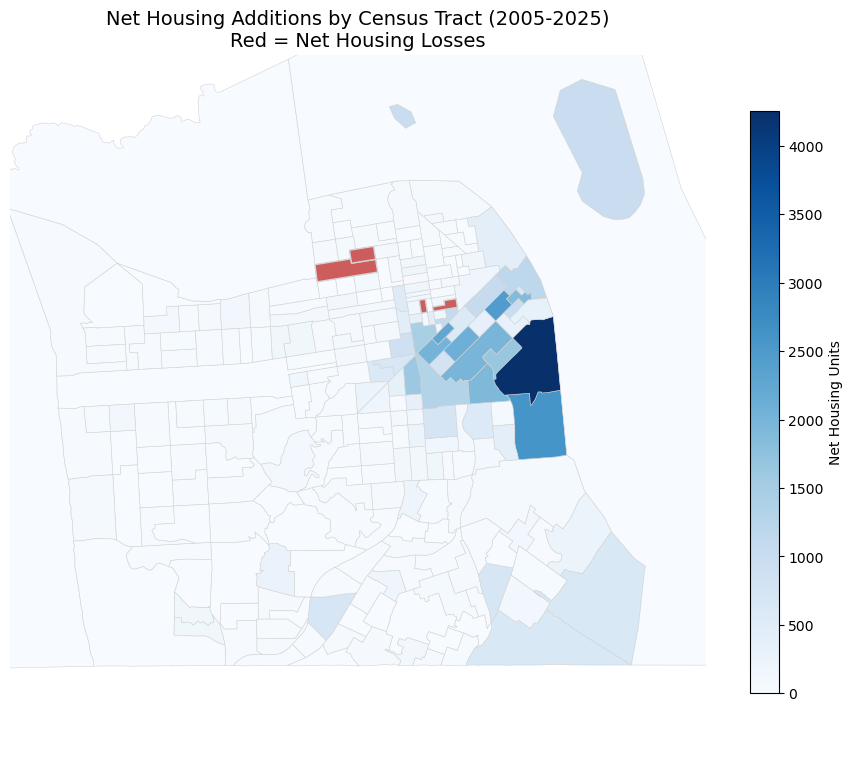

In [18]:
# Visualization 1: Net Housing Additions by Census Tract (2005-2025)
import matplotlib.pyplot as plt

# Create the map
fig, ax = plt.subplots(figsize=(9, 10))

# Plot net housing additions
tract_production.plot(
    column="net_units_added_2005_2025",
    cmap="Blues",
    vmin=0,
    legend=True,
    legend_kwds={"shrink": 0.6, "label": "Net Housing Units"},
    ax=ax,
    edgecolor="lightgray",
    linewidth=0.4
)

# Highlight tracts with negative net housing changes
tract_production[tract_production["net_units_added_2005_2025"] < 0 ].plot(ax=ax, color="indianred", edgecolor="lightgray")

# Focus on mainland San Francisco
ax.set_xlim(-122.53, -122.34)
ax.set_ylim(37.69, 37.84)

# Add title and remove axes
ax.set_title("Net Housing Additions by Census Tract (2005-2025)\nRed = Net Housing Losses",fontsize=14)
ax.set_axis_off()

# Save and display
plt.tight_layout()
plt.savefig("historical_net_additions_map.png", dpi=300, bbox_inches="tight")
plt.show()


<a id="step-6"></a>
## Step 6 — Classify tracts using ACS 2020–2024 

clean B25003, clean B19013, merge by GEOID, then use `pd.qcut()` to divide tracts into three income groups and three renter-share groups. We use the **same ACS 2024 five-year data** already in this project's `data/raw` folder, so no extra copies or folder changes are needed. The groups describe **2020–2024 conditions**, not neighborhood conditions in 2005.

In [19]:
tenure = pd.read_csv("B25003/ACSDT5Y2024.B25003-Data.csv", skiprows=[1])
tenure

,GEO_ID,NAME,B25003_001E,B25003_001M,B25003_002E,B25003_002M,B25003_003E,B25003_003M,Unnamed: 8
0,0400000US06,California,13548091,17724,7567568,37334,5980523,22985,NaN
1,0500000US06075,"San Francisco County, California",363970,1953,139057,2183,224913,2332,NaN
2,1400000US06001400100,Census Tract 4001; Alameda County; California,1337,152,1256,146,81,53,NaN
3,1400000US06001400200,Census Tract 4002; Alameda County; California,879,90,537,59,342,88,NaN
4,1400000US06001400300,Census Tract 4003; Alameda County; California,2888,263,1245,200,1643,232,NaN
...,...,...,...,...,...,...,...,...,...
9370,1400000US06075980501,Census Tract 9805.01; San Francisco County; Ca...,115,48,0,14,115,48,NaN
9371,1400000US06075980600,Census Tract 9806; San Francisco County; Calif...,577,72,382,76,195,60,NaN
9372,1400000US06075980900,Census Tract 9809; San Francisco County; Calif...,238,77,23,25,215,73,NaN
9373,1400000US06075990100,Census Tract 9901; San Francisco County; Calif...,0,14,0,14,0,14,NaN


In [20]:
# Step 6a: Read 2020-2024 ACS tenure (B25003).
tenure = pd.read_csv("B25003/ACSDT5Y2024.B25003-Data.csv", skiprows=[1])
tenure = tenure.loc[tenure["GEO_ID"].str.startswith("1400000US06075")].copy()
tenure["GEOID"] = tenure["GEO_ID"].str[-11:]
tenure = tenure.drop_duplicates(subset="GEOID")

# convert to numeric
tenure["total"] = pd.to_numeric(tenure["B25003_001E"], errors="coerce")
tenure["renter"] = pd.to_numeric(tenure["B25003_003E"], errors="coerce")

# filter
tenure = tenure.loc[(tenure["total"] > 0) & tenure["renter"].between(0, tenure["total"])].copy()

# Renter share = renter-occupied units / total occupied units.
tenure["renter_share"] = tenure["renter"] / tenure["total"]

tenure = tenure[["GEOID", "renter_share"]]

print("Valid tenure tracts:", len(tenure))

Valid tenure tracts: 240


In [21]:
# Step 6b: Read 2020-2024 ACS median income (B19013).
income = pd.read_csv("data/raw/ACSDT5Y2024.B19013-Data.csv", skiprows=[1])
income

,GEO_ID,NAME,B19013_001E,B19013_001M,Unnamed: 4
0,0400000US06,California,99122,310,NaN
1,0500000US06075,"San Francisco County, California",140970,2593,NaN
2,1400000US06001400100,Census Tract 4001; Alameda County; California,"250,000+",***,NaN
3,1400000US06001400200,Census Tract 4002; Alameda County; California,208438,35560,NaN
4,1400000US06001400300,Census Tract 4003; Alameda County; California,176618,34769,NaN
...,...,...,...,...,...
9370,1400000US06075980501,Census Tract 9805.01; San Francisco County; Ca...,12908,1255,NaN
9371,1400000US06075980600,Census Tract 9806; San Francisco County; Calif...,154375,47835,NaN
9372,1400000US06075980900,Census Tract 9809; San Francisco County; Calif...,-,**,NaN
9373,1400000US06075990100,Census Tract 9901; San Francisco County; Calif...,-,**,NaN


In [22]:
income = income.loc[income["GEO_ID"].str.startswith("1400000US06075")].copy()
income["GEOID"] = income["GEO_ID"].str[-11:]
income = income.drop_duplicates(subset="GEOID")


# Clean income values and convert to numbers.
income["median_income"] = pd.to_numeric(income["B19013_001E"].str.replace(",", "", regex=False).str.replace("+", "", regex=False),errors="coerce")

# Keep tracts with valid income estimates.
income_clean = income.loc[income["median_income"].notna(),["GEOID", "median_income"]].copy()

print("Valid income tracts:", len(income_clean))
income_clean.head()


Valid income tracts: 234


,GEOID,median_income
7059,06075010101,89022.0
7060,06075010102,102826.0
7061,06075010201,156017.0
7062,06075010202,176958.0
7063,06075010300,158144.0


In [23]:
# Step 6c: Merge the two ACS tables by tract GEOID.
merged = tenure.merge(income_clean, on="GEOID", how="inner")

# Divide the same tracts into three equal-sized income and renter-share groups.
merged["income_group"] = pd.qcut(merged["median_income"], 3, labels=["low", "middle", "high"])
merged["renter_group"] = pd.qcut(merged["renter_share"], 3, labels=["low_renter", "middle_renter", "high_renter"])

print("Tracts with both ACS measures:", len(merged))
print("Income groups:\n", merged["income_group"].value_counts().sort_index())
print("Renter groups:\n", merged["renter_group"].value_counts().sort_index())


Tracts with both ACS measures: 234
Income groups:
 income_group
low       78
middle    78
high      78
Name: count, dtype: int64
Renter groups:
 renter_group
low_renter       78
middle_renter    78
high_renter      78
Name: count, dtype: int64


In [24]:
# Join ACS groups with Housing Production data

# Merge ACS income and renter groups with housing production by GEOID.
# Keep all Census Tracts using a left join.
master = tract_production.merge(merged[["GEOID", "median_income", "renter_share", "income_group", "renter_group"]], on="GEOID",how="left")

# Replace missing ACS groups with "unclassified".
for column in ["income_group", "renter_group"]:
    groups = []
    for group in master[column]:
        if pd.isna(group):
            groups.append("unclassified")
        else:
            groups.append(group)

    master[column] = groups

# Save the results without the geometry column.
master.drop(columns="geometry").to_csv("data/processed/tract_acs_groups.csv", index=False)

# Check the number of Census Tracts.
print("Total tracts:", len(master))
print("Tracts with ACS groups:", len(merged))

# Display the first five rows.
master[["GEOID", "median_income", "renter_share", "income_group", "renter_group"]].head()


Total tracts: 244
Tracts with ACS groups: 234


,GEOID,median_income,renter_share,income_group,renter_group
0,06075980501,12908.0,1.000000,low,high_renter
1,06075017102,173594.0,0.658052,middle,middle_renter
2,06075012302,44954.0,1.000000,low,high_renter
3,06075016801,123147.0,0.823387,middle,high_renter
4,06075011902,75625.0,0.931232,low,high_renter


<a id="step-7"></a>
## Step 7 — Housing additions by 2020–2024 ACS groups

Sum the **2005–2025 signed net additions** from Steps 4–5 for the income and renter-share groups from Step 6.
Keep unclassified tracts and unassigned housing records visible in the summary. The ACS groups describe **2020–2024**, not 2005.


In [25]:
# Step 7a: Sum net housing additions for each 2020-2024 income group.
income_summary = master.groupby("income_group", as_index=False).agg(tracts=("GEOID", "size"), production_records=("production_records", "sum"), net_units=("net_units_added_2005_2025", "sum")).rename(columns={"income_group": "group"})
income_summary["dimension"] = "income"

# Repeat for the renter-share groups.
renter_summary = master.groupby("renter_group", as_index=False).agg(
    tracts=("GEOID", "size"),
    production_records=("production_records", "sum"),
    net_units=("net_units_added_2005_2025", "sum")
).rename(columns={"renter_group": "group"})
renter_summary["dimension"] = "renter"

# Housing records without GEOID are outside both group comparisons.
unassigned = pd.DataFrame({
    "group": ["unassigned_to_tract", "unassigned_to_tract"],
    "tracts": [0, 0],
    "production_records": [detailed["GEOID"].isna().sum()] * 2,
    "net_units": [unassigned_net_units] * 2,
    "dimension": ["income", "renter"]
})

group_comparison = pd.concat([income_summary, renter_summary, unassigned], ignore_index=True)
group_comparison["share_city_net_pct"] = group_comparison["net_units"] / city_net_units * 100

group_comparison.to_csv("data/processed/group_housing_comparisons.csv", index=False)
group_comparison


,group,tracts,production_records,net_units,dimension,share_city_net_pct
0,high,78,2054,22495,income,38.796523
1,low,78,1560,15562,income,26.839364
2,middle,78,2312,17528,income,30.230071
3,unclassified,10,33,1571,income,2.709462
4,high_renter,78,1416,27660,renter,47.704460
5,low_renter,78,2431,7669,renter,13.226519
6,middle_renter,78,2079,20256,renter,34.934980
7,unclassified,10,33,1571,renter,2.709462
8,unassigned_to_tract,0,22,826,income,1.424580
9,unassigned_to_tract,0,22,826,renter,1.424580


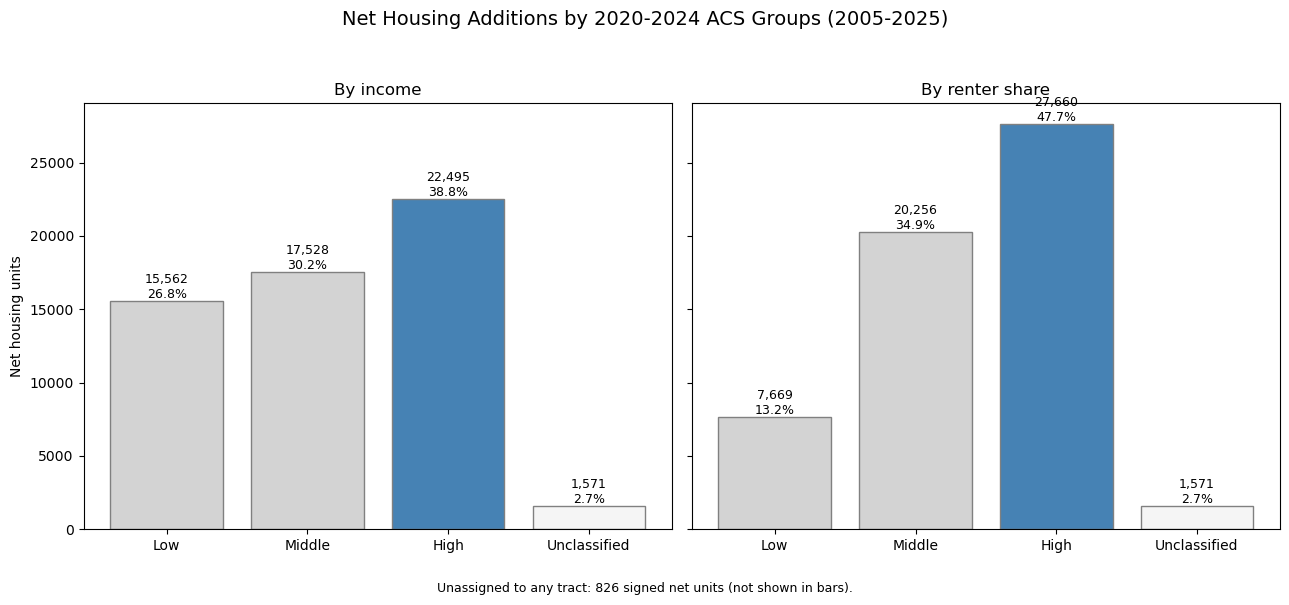

In [26]:
# Figure 2: Net housing additions by recent income and renter-share groups.
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)

for ax, dimension, order, title in [
    (axes[0], "income", ["low", "middle", "high", "unclassified"], "By income"),
    (axes[1], "renter", ["low_renter", "middle_renter", "high_renter", "unclassified"], "By renter share")
]:
    # Put categories in the same order on both charts.
    subset = group_comparison.loc[group_comparison["dimension"] == dimension].set_index("group").reindex(order)
    bars = ax.bar([0, 1, 2, 3], subset["net_units"], color=["lightgray", "lightgray", "steelblue", "whitesmoke"], edgecolor="gray")
    ax.set_xticks([0, 1, 2, 3], ["Low", "Middle", "High", "Unclassified"])
    ax.set_title(title)
    ax.set_ylabel("Net housing units" if dimension == "income" else "")

    # Label each bar with net units and its share of the citywide net total.
    for bar, units, share in zip(bars, subset["net_units"], subset["share_city_net_pct"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{units:,.0f}\n{share:.1f}%", ha="center", va="bottom", fontsize=9)

fig.suptitle("Net Housing Additions by 2020-2024 ACS Groups (2005-2025)", fontsize=14)
fig.text(0.5, 0.01, f"Unassigned to any tract: {unassigned_net_units:,.0f} signed net units (not shown in bars).", ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.savefig("housing_additions_by_acs_groups.png", dpi=300, bbox_inches="tight")
plt.show()


### Step 7b — Historical sensitivity: 2006–2010 vs. 2020–2024 ACS

Use the **same tract net additions from the simplified Step 5** and compare income/renter groups from two ACS periods.
Only census tracts with unchanged boundaries between 2010 and 2020 and valid estimates in both periods are compared.

Required existing files in `data/raw/`: `g20105ca.csv`, `20105ca0053000.zip`, `20105ca0095000.zip`, and `tract2020_to_2010_california.txt`.


In [27]:
# Step 7b: 2006-2010 ACS Historical Comparison

# 1. Read and clean B25003 (Renter Share)
tenure_2010 = pd.read_csv("data/raw/ACSDT5Y2010.B25003-Data.csv",skiprows=[1])

# Keep San Francisco Census Tracts
tenure_2010 = tenure_2010[tenure_2010["GEO_ID"].str.startswith("1400000US06075")].copy()
tenure_2010["GEOID_2010"] = tenure_2010["GEO_ID"].str[-11:]

# convert to numeric
tenure_2010["total"] = pd.to_numeric(tenure_2010["B25003_001E"], errors="coerce")
tenure_2010["renter"] = pd.to_numeric(tenure_2010["B25003_003E"], errors="coerce")

# Calculate renter share
tenure_2010 = tenure_2010[tenure_2010["total"] > 0].copy()
tenure_2010["renter_share_2010"] = (tenure_2010["renter"] / tenure_2010["total"])


# 2. Read and clean B19013 (Median Household Income)
income_2010 = pd.read_csv("data/raw/ACSDT5Y2010.B19013-2026-10-07T063123.csv")

# Same method as Step 6 EDA
records = []


# Convert Census Tract names to 11-digit GEOIDs.
def name_to_geoid(name):
    tract = name.split("Census Tract ")[1].split(";")[0]
    parts = tract.split(".")
    if len(parts) == 2:
        tract_code = parts[0].zfill(4) + (parts[1] + "00")[:2]
    else:
        tract_code = parts[0].zfill(4) + "00"
    return "06075" + tract_code


for col in income_2010.columns:
    if "Census Tract" in col and "San Francisco" in col and "!!Estimate" in col:
        records.append({
            "GEOID_2010": name_to_geoid(col),
            "median_income_2010": income_2010[col].iloc[0]
        })

old_income = pd.DataFrame(records)

# Clean income values
old_income["median_income_2010"] = pd.to_numeric(
    old_income["median_income_2010"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
)

old_income.loc[old_income["median_income_2010"] < 0, "median_income_2010"] = np.nan


# 3. Merge the two ACS datasets
old_acs = tenure_2010[["GEOID_2010", "renter_share_2010"]].merge(
    old_income[["GEOID_2010", "median_income_2010"]],
    on="GEOID_2010",
    how="inner"
)

print("2006-2010 SF tracts:", len(old_acs))
old_acs.head()


2006-2010 SF tracts: 176


,GEOID_2010,renter_share_2010,median_income_2010
0,06075011901,0.731844,50769.0
1,06075011902,0.956970,51029.0
2,06075012201,0.934124,31265.0
3,06075012202,0.992773,23716.0
4,06075012301,0.992281,13615.0


In [28]:
# Step 7b: Compare 2006-2010 and 2020-2024 ACS data

# Remove identical duplicate rows from the 2010 ACS data.
old_acs = old_acs.drop_duplicates()

# Check whether each GEOID appears only once.
print("2010 ACS records:", len(old_acs))
print("Unique 2010 GEOIDs:", old_acs["GEOID_2010"].nunique())

# Match Census Tracts using the same GEOID.
historical = master.merge(
    old_acs,
    left_on="GEOID",
    right_on="GEOID_2010",
    how="inner"
)

# Keep tracts with valid ACS data in both periods.
historical = historical.dropna(subset=[
    "median_income",
    "renter_share",
    "median_income_2010",
    "renter_share_2010"
])

# Check the comparison results.
print("Matched records:", len(historical))
print("Unique matched GEOIDs:", historical["GEOID"].nunique())
print("Net units:", historical["net_units_added_2005_2025"].sum())

historical.head()


2010 ACS records: 88
Unique 2010 GEOIDs: 88
Matched records: 78
Unique matched GEOIDs: 78
Net units: 6735


,tract_name,intptlon,awater,mtfcc,aland,namelsad,tractce,statefp,data_loaded_at,intptlat,...,negative_net_units_abs,net_units_added_2005_2025,production_records,median_income,renter_share,income_group,renter_group,GEOID_2010,renter_share_2010,median_income_2010
0,9805.01,-122.4193463,9769.0,G5020,1471536.0,Census Tract 9805.01,980501,06,2022-03-04,+37.7162081,...,0,0,0,12908.0,1.000000,low,high_renter,06075980501,0.705455,17781.0
1,171.02,-122.4504754,0.0,G5020,294894.0,Census Tract 171.02,017102,06,2022-03-04,+37.7654353,...,10,16,29,173594.0,0.658052,middle,middle_renter,06075017102,0.673575,105684.0
2,123.02,-122.4120970,0.0,G5020,92653.0,Census Tract 123.02,012302,06,2022-03-04,+37.7870222,...,1,122,3,44954.0,1.000000,low,high_renter,06075012302,1.000000,24375.0
3,168.01,-122.4290133,0.0,G5020,226534.0,Census Tract 168.01,016801,06,2022-03-04,+37.7713309,...,2,610,33,123147.0,0.823387,middle,high_renter,06075016801,0.788991,72724.0
4,119.02,-122.4098067,0.0,G5020,93053.0,Census Tract 119.02,011902,06,2022-03-04,+37.7909959,...,0,84,9,75625.0,0.931232,low,high_renter,06075011902,0.956970,51029.0


In [29]:
# Step 7b: Classify the same comparable tracts separately for each ACS period.
# The housing totals do not change, only the income/renter-share group labels.
historical["income_group_2010"] = pd.qcut(historical["median_income_2010"], 3, labels=["low", "middle", "high"])
historical["income_group_2024"] = pd.qcut(historical["median_income"], 3, labels=["low", "middle", "high"])
historical["renter_group_2010"] = pd.qcut(historical["renter_share_2010"], 3, labels=["low", "middle", "high"])
historical["renter_group_2024"] = pd.qcut(historical["renter_share"], 3, labels=["low", "middle", "high"])

print("Comparable tracts:", len(historical))
print("Income group unchanged:", (historical["income_group_2010"] == historical["income_group_2024"]).sum())
print("Renter group unchanged:", (historical["renter_group_2010"] == historical["renter_group_2024"]).sum())
historical.to_csv("data/processed/historical_acs_comparison.csv", index=False)


Comparable tracts: 78
Income group unchanged: 50
Renter group unchanged: 62


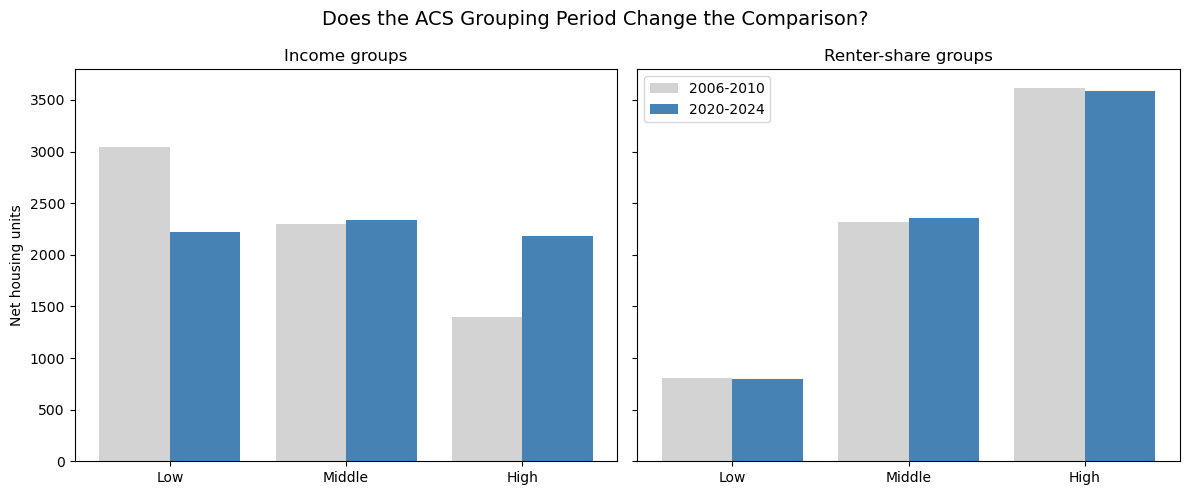

In [30]:
# Figure 3: Compare two ACS periods using the same tracts and same housing totals.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
order = ["low", "middle", "high"]

for ax, old_group, new_group, title in [
    (axes[0], "income_group_2010", "income_group_2024", "Income groups"),
    (axes[1], "renter_group_2010", "renter_group_2024", "Renter-share groups")
]:
    early = historical.groupby(old_group, observed=False)["net_units_added_2005_2025"].sum().reindex(order)
    recent = historical.groupby(new_group, observed=False)["net_units_added_2005_2025"].sum().reindex(order)
    ax.bar([0, 1, 2], early, width=0.4, color="lightgray", label="2006-2010")
    ax.bar([0.4, 1.4, 2.4], recent, width=0.4, color="steelblue", label="2020-2024")
    ax.set_xticks([0.2, 1.2, 2.2], ["Low", "Middle", "High"])
    ax.set_title(title)
    ax.set_ylabel("Net housing units" if old_group == "income_group_2010" else "")

axes[1].legend()
plt.suptitle("Does the ACS Grouping Period Change the Comparison?", fontsize=14)
plt.tight_layout()
plt.savefig("historical_acs_grouping_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## Extra visualization A — Distribution of net housing additions (histogram + KDE)

This uses the **same histogram/KDE style** as the sample `baseline_2005_stock` plot, but it uses the housing variable actually available in this project: `net_units_added_2005_2025`. It must **not** be labeled "2005 baseline housing stock" because the project does not have a verified 2005 stock estimate.

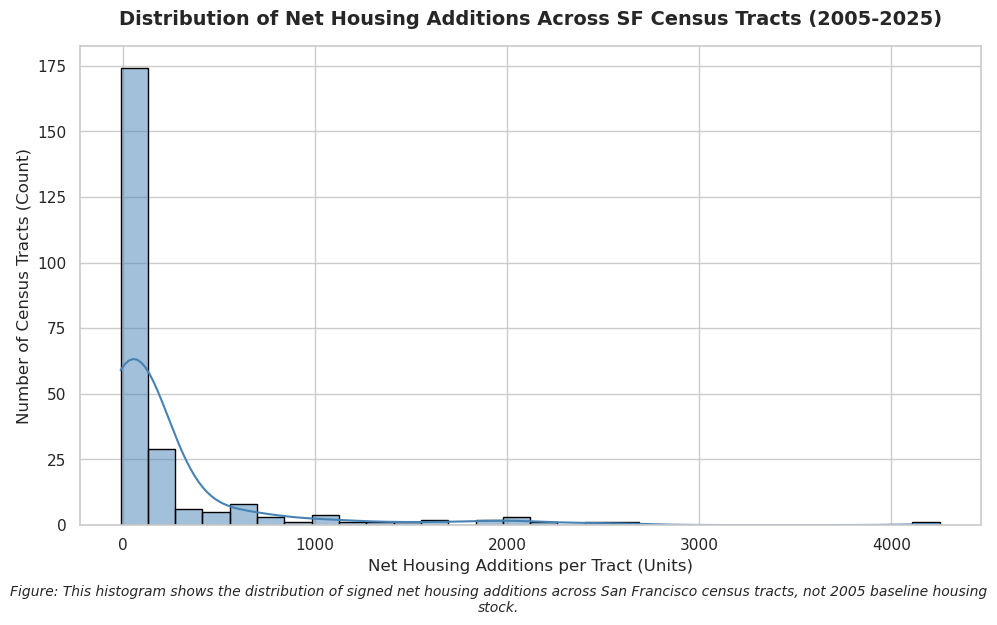

In [31]:
# Histogram: distribution of 2005-2025 net housing additions across tracts
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.histplot(tract_production["net_units_added_2005_2025"],bins=30, kde=True, color="steelblue", edgecolor="black")

plt.title("Distribution of Net Housing Additions Across SF Census Tracts (2005-2025)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Net Housing Additions per Tract (Units)", fontsize=12)
plt.ylabel("Number of Census Tracts (Count)", fontsize=12)

plt.figtext(0.5, -0.03,
    "Figure: This histogram shows the distribution of signed net housing additions across San Francisco census tracts, not 2005 baseline housing stock.",
    wrap=True, horizontalalignment="center", fontsize=10, fontstyle="italic")

plt.tight_layout()
plt.savefig("net_housing_additions_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Extra visualization B — Top 10 tracts by net housing additions (horizontal bar chart)

Same layout as the sample `growth_rate_pct` plot; because no reliable `baseline_2005_stock` exists, the chart ranks **absolute net housing additions**, not percentage housing growth.

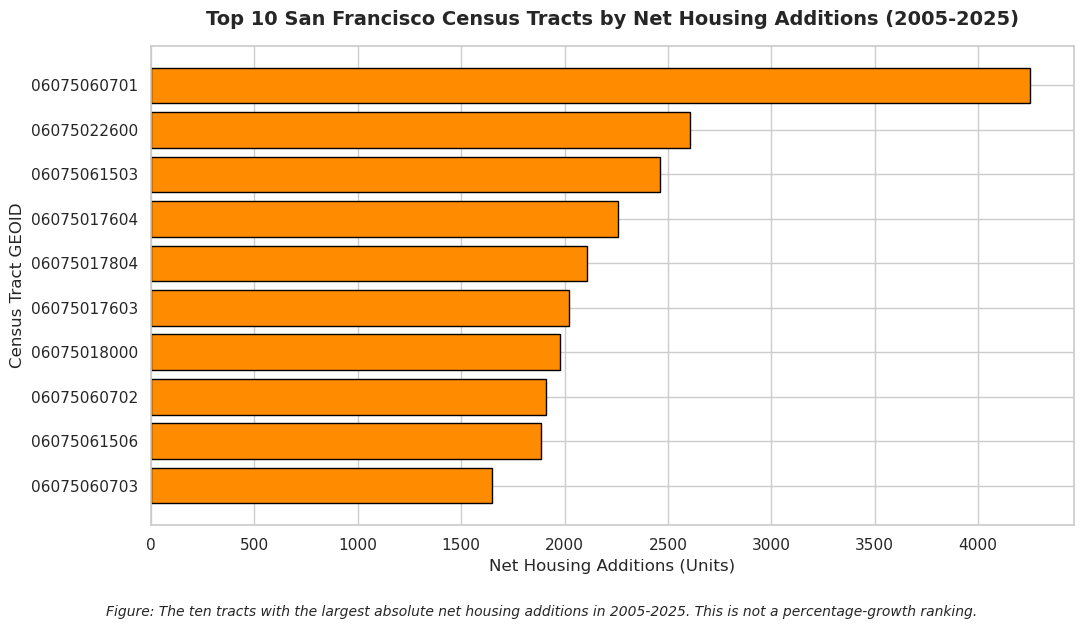

In [32]:
# Horizontal bars: top 10 tracts by net housing additions, not growth rates
top_growth = tract_production.nlargest(10, "net_units_added_2005_2025")
plt.figure(figsize=(11, 6))
plt.barh(
    y=top_growth["GEOID"].astype(str),
    width=top_growth["net_units_added_2005_2025"],
    color="darkorange", edgecolor="black"
)
plt.gca().invert_yaxis()
plt.title("Top 10 San Francisco Census Tracts by Net Housing Additions (2005-2025)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Net Housing Additions (Units)", fontsize=12)
plt.ylabel("Census Tract GEOID", fontsize=12)
plt.figtext(0.5, -0.04,
    "Figure: The ten tracts with the largest absolute net housing additions in 2005-2025. This is not a percentage-growth ranking.",
    wrap=True, horizontalalignment="center", fontsize=10, fontstyle="italic")
plt.tight_layout()
plt.savefig("top_10_net_housing_additions_tracts.png", dpi=300, bbox_inches="tight")
plt.show()